## **Statistical judgement**

Marketing managers need to make decisions based on data. Nevertheless, I think this field has usually not been as data driven as it should have. Additionally managers should should have statistical intuition:

Normally, they fail to make judgements on the following:
- Variance
- Correlation
- Point predictions
- Non linearity

The purpose of the following notebook is to explore the judgement of variance.



## Judgements of variance

Recall that the standard deviation is the square root of the variance

The standard error measures how much an estimate, usually the sample mean, would vary if you repeated the sampling many times

**Formula:** SE = s / √n

To this latest one, it was name the most dangerous equation, and with good reason. More on this later.

1) Lets imagine we sample the performance of students follows a normal distribution and so do schools sizes. But there is no connection between performance and school size.

We generate some data below:

In [128]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

school_sizes= np.round(np.random.normal(500, 150, 1000))
school_scores=[]

for i in school_sizes:
  school_score=np.random.normal(70,10,int(i))
  school_scores.append(school_score.mean())


df=pd.DataFrame({'school_size':school_sizes,'school_score':school_scores})
df.head()

,school_size,school_score
0,574.0,71.227648
1,310.0,70.999265
2,615.0,70.149737
3,838.0,70.165431
4,581.0,70.218302


We run a regression between school size and scores. as expected, **no relationship** between them is found because we made sure in the data that it does not exist.

In [143]:
regression=smf.ols('school_score ~ school_size', data=df).fit()
regression.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           school_score   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.001
Method:                 Least Squares   F-statistic:                   0.03490
Date:                Tue, 10 Nov 2026   Prob (F-statistic):              0.852
Time:                        12:42:23   Log-Likelihood:                -966.87
No. Observations:                1000   AIC:                             1938.
Df Residuals:                     998   BIC:                             1948.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      70.0179      0.040   1754.490      0.000      69.940      70.096
school_size  1.311e-05   7.02e-05      0.187      0.852      -0.000       0.000
==============================================================================
Omnibus:                       94.929   Durbin-Watson:                   1.840
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              395.839
Skew:                          -0.347   Prob(JB):                     1.11e-86
Kurtosis:                       6.003   Cond. No.                     1.13e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.13e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

We plot the relationship between those variables and we find nothing.

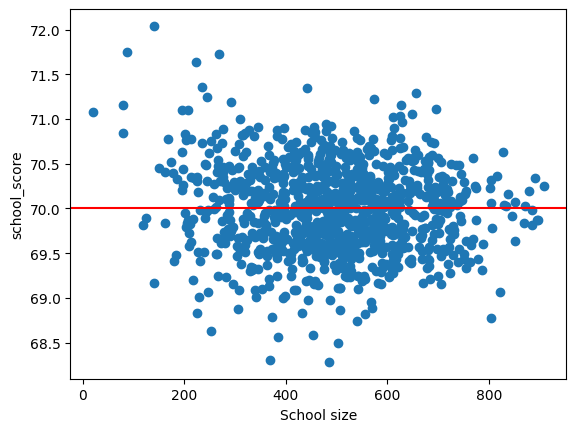

In [130]:
plt.scatter(df['school_size'], df['school_score'])
plt.axhline(70, color='red')
plt.xlabel('School size')
plt.ylabel('school_score')
plt.show()

Coming back to the equations mentioned above, we estimate the variance, standard deviation and standard error for the total population vs a sample of it.

The interesting about this is the big difference between SE between a sample and the population. How can this be?

Recall that standard error measures how much an estimate would vary if you repeated the sampling many times.

In other words:
- Imagine you take the average of a small sample of the population
- You get a number and assume it's true for the whole population
- But that average is noisy: the smaller the sample, the more it bounces around, because

  SE = σ / √n

  so a sample of 10 has an SE ~10× bigger than a sample of 1000
  
- This means small groups (schools, hospitals, towns) end up at **both extremes** of any ranking just by chance
- The common mistake: seeing that the top performers are small and concluding that "small is better", when small groups are just noisier. They're also at the bottom.

In [144]:
small = df[df['school_size'] < 200]
large = df[df['school_size'] > 800]
print('Small: SD', small['school_score'].std(), '| expected', 10/np.sqrt(small['school_size'].mean()))
print('Large: SD', large['school_score'].std(), '| expected', 10/np.sqrt(large['school_size'].mean()))


Small: SD 1.0462857949954225 | expected 0.9623989784717705
Large: SD 0.33612476911815203 | expected 0.33324509358054666


Lets see this in an example:

Lets get the top 5% highest schools and see their sizes and compare it to the average size (500)

In [132]:
#performance of top 5% performers and their sizes:

top_5=df[['school_score','school_size']].sort_values(by='school_score', ascending=False).head(50)

print('Size of top performers:')
print('Average size of top performers:',top_5['school_size'].mean())
print('Average performance of top 5:',top_5['school_score'].mean())



Size of top performers:
Average size of top performers: 400.14
Average performance of top 5: 71.02553841070772


It looks like the top 5% of performers tend to be smaller schools. Now lets test the opposite. How do top 5% of worst schools look like?

In [133]:
#performance of top 5% performers and their sizes:

top_5=df[['school_score','school_size']].sort_values(by='school_score', ascending=True).head(50)

print('Size of top performers:')
print('Average size of top performers:',top_5['school_size'].mean())
print('Average performance of top 5:',top_5['school_score'].mean())



Size of top performers:
Average size of top performers: 451.48
Average performance of top 5: 68.9849562194967


It turns out that the worst performers are also small schools!

Running a simulation of different processes we see this in action:

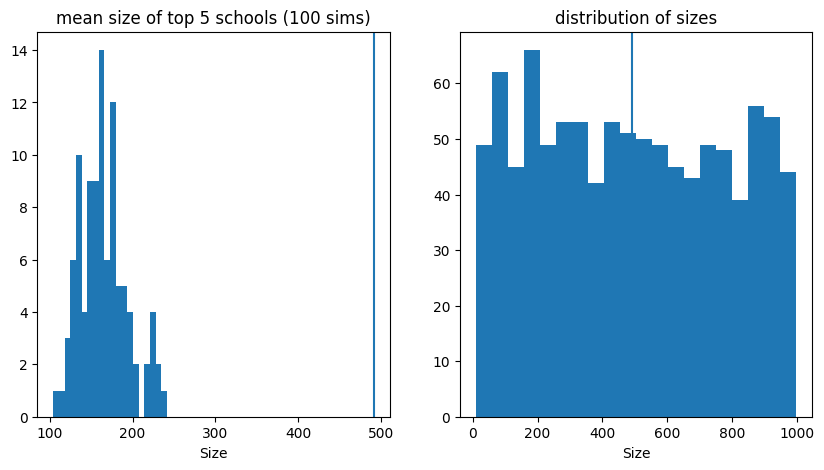

In [145]:
def top_5_size(seed):
    np.random.seed(seed)
    size = np.random.randint(10, 1000, 1000)
    score = np.random.normal(70, 10 / np.sqrt(size))
    df_sim = pd.DataFrame({'school_score': score, 'school_size': size})
    top_5 = df_sim.sort_values('school_score', ascending=False).head(50)
    return top_5['school_size'].mean(), df_sim

vector = []
for i in range(100):
    m, df_sim = top_5_size(i)
    vector.append(m)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('mean size of top 5 schools (100 sims)')
plt.hist(vector, bins=20)
plt.axvline(df['school_size'].mean())
plt.xlabel('Size')
plt.subplot(1, 2, 2)
plt.title('distribution of sizes')
plt.hist(df['school_size'], bins=20)
plt.axvline(df['school_size'].mean())
plt.xlabel('Size')
plt.show()

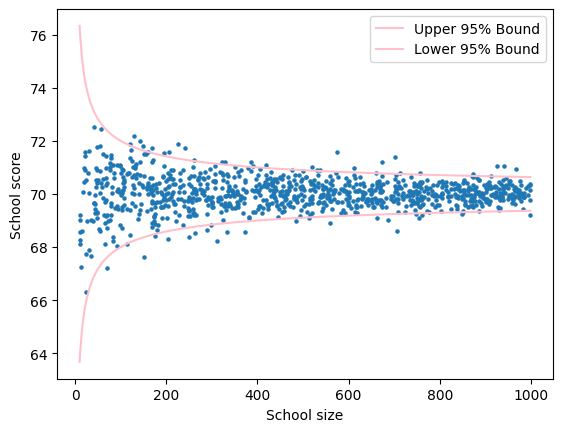

In [140]:
df = df.sort_values('school_size')
# Calculate the expected standard error for each school size
df['se'] = 10 / np.sqrt(df['school_size'])

plt.scatter(df['school_size'], df['school_score'], s=5)
plt.plot(df['school_size'], 70 + 2*df['se'], color='pink', label='Upper 95% Bound')
plt.plot(df['school_size'], 70 - 2*df['se'], color='pink', label='Lower 95% Bound')
plt.xlabel('School size')
plt.ylabel('School score')
plt.legend()
plt.show()

Conclusion:

When you analyst comes and tell you the top X% of campaings are the ones in which we reached a small population. Beware, cause this might be to the fact of Standard errors.

In such case:
- A campaings performance is measured as the purchase rate
- They targetted a small sample of individuals and therefore SE is high.
- You but that campaigns for small audiences perform better
- You're toast

Before doing so, you might want to:
- Check the bottom of the ranking too
- Ask for confidence intervals
- Regress the outcome on size, using all campaigns
